# E. coli datasets in torchcell

Four built *Escherichia coli* K-12 datasets, loaded from the public `tc-data` endpoint, printed and plotted. Run the cells top to bottom in an empty directory with `torchcell` installed (Python 3.13 or newer). The stores download into `./data/torchcell/` and the figures are written to `./figures/`.

The outputs below are from one run of the same code as a script, `experiments/034-showcase-datasets/scripts/ecoli_download_tutorial.py`.

## Setup

Setting `TC_DATA_URL` makes each loader download its built store.

In [1]:
import hashlib
import json
import os
import sys
import time
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.figure import Figure

from torchcell.datasets.artifact import content_sha256
from torchcell.datasets.client import DatasetClient
from torchcell.datasets.ecoli.babu2014 import GeneInteractionBabu2014Dataset
from torchcell.datasets.ecoli.campos2018 import (
    FEATURE_UNITS,
    GrowthRateCampos2018Dataset,
    MorphologyCampos2018Dataset,
)
from torchcell.datasets.ecoli.fuhrer2017 import MetabolomeFuhrer2017Dataset
from torchcell.endpoint_http import DEFAULT_URL
from torchcell.utils import PANEL_WIDTHS_MM, PLOT_PALETTE, mm_to_in, panel_label

# A loader downloads its built store only when TC_DATA_URL is set. Without it the loader
# builds the store from the publisher's files, which is the developer path.
os.environ.setdefault("TC_DATA_URL", DEFAULT_URL)

DATA = Path("data/torchcell")  # each dataset unpacks into DATA/<slug>/
SECONDS: dict[str, float] = {}  # slug -> seconds to download, verify, unpack and open

Figure style: one row of three panels, colors from the torchcell palette.

In [2]:
ORANGE, RED, PURPLE, YELLOW, BLUE, GRAY = PLOT_PALETTE[:6]
plt.rcParams.update(
    {
        "font.family": ["Arial", "DejaVu Sans"],
        "font.size": 7,
        "axes.labelsize": 7,
        "axes.titlesize": 7,
        "xtick.labelsize": 7,
        "ytick.labelsize": 7,
        "legend.fontsize": 7,
        "axes.linewidth": 0.5,
        "xtick.major.width": 0.5,
        "ytick.major.width": 0.5,
        "legend.frameon": False,
        "svg.fonttype": "none",  # text stays text in the SVG
        "svg.hashsalt": "torchcell",  # the same bytes on every run
    }
)
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)


def three_panels() -> tuple[Figure, Any]:
    """One row of three panels, 179 mm wide."""
    return plt.subplots(
        1,
        3,
        figsize=(mm_to_in(PANEL_WIDTHS_MM["full"]), mm_to_in(54)),
        layout="constrained",
    )


def save(figure: Figure, name: str) -> None:
    """Letter the panels a to c and write figures/<name>.svg and .png."""
    for axis, letter in zip(figure.axes, "abc", strict=True):
        panel_label(axis, letter)
    figure.savefig(FIGURES / f"{name}.svg", metadata={"Date": None})
    figure.savefig(FIGURES / f"{name}.png", dpi=200)
    plt.close(figure)

## What the endpoint serves

In [3]:
client = DatasetClient.from_env()
print("endpoint", client.url)
SLUGS = (
    "ecoli_growth_rate_campos2018",
    "ecoli_morphology_campos2018",
    "gene_interaction_babu2014",
    "metabolome_fuhrer2017",
)
for slug in SLUGS:
    artifact = client.select(slug)  # newest archive the installed major.minor reads
    if artifact is None:
        raise SystemExit(f"{client.url} serves no {slug} archive this torchcell reads")
    print(slug)
    print(f"  loader   {artifact.dataset_class}")
    print(f"  archive  {artifact.archive}  ({artifact.archive_bytes:,} bytes)")
    print(f"  records  {artifact.n_experiments:,}")
    print(f"  release  knowledge graph {artifact.kg_version} ({artifact.kg_release})")

endpoint http://torchcell-database.ncsa.illinois.edu:8724
ecoli_growth_rate_campos2018
  loader   GrowthRateCampos2018Dataset
  archive  ecoli_growth_rate_campos2018-1.8.4-ef455265.tar.xz  (144,152 bytes)
  records  3,664
  release  knowledge graph 4.0 (2026.10.17-4295f7ca)
ecoli_morphology_campos2018
  loader   MorphologyCampos2018Dataset
  archive  ecoli_morphology_campos2018-1.8.4-52643bef.tar.xz  (856,456 bytes)
  records  3,664
  release  knowledge graph 4.0 (2026.10.17-4295f7ca)
gene_interaction_babu2014
  loader   GeneInteractionBabu2014Dataset
  archive  gene_interaction_babu2014-1.8.4-412a73ed.tar.xz  (1,049,192 bytes)
  records  42,705
  release  knowledge graph 4.0 (2026.10.17-4295f7ca)
metabolome_fuhrer2017
  loader   MetabolomeFuhrer2017Dataset
  archive  metabolome_fuhrer2017-1.8.4-7eb33983.tar.xz  (81,780,576 bytes)
  records  3,806
  release  knowledge graph 4.0 (2026.10.17-4295f7ca)


## Growth rate (Campos 2018)

One record per Keio strain. The label is the maximal growth rate relative to the parent strain BW25113.

In [4]:
started = time.perf_counter()
growth = GrowthRateCampos2018Dataset(root=str(DATA / "ecoli_growth_rate_campos2018"))
SECONDS["ecoli_growth_rate_campos2018"] = time.perf_counter() - started
print(f"{len(growth):,} records")

3,664 records


One record, field by field.

In [5]:
record = growth[0]  # a dict with three keys: experiment, reference, publication
deletion = record["experiment"]["genotype"]["perturbations"][0]
environment = record["experiment"]["environment"]
phenotype = record["experiment"]["phenotype"]
print("gene       ", deletion["perturbed_gene_name"], deletion["systematic_gene_name"])
print("strain     ", deletion["collection"], "plate", deletion["construction"]["plate"])
print("medium     ", environment["media"]["name"])
print(
    "temperature",
    environment["temperature"]["value"],
    environment["temperature"]["unit"],
)
print(
    "fitness    ", phenotype["fitness"], "from", phenotype["n_samples"], "growth curve"
)
print("wild type  ", record["reference"]["phenotype_reference"]["fitness"])
print("genome     ", record["reference"]["genome_reference"]["assembly_accession"])
print("source     ", record["publication"]["doi_url"])

gene        hchA BW25113_1967
strain      Keio collection plate 1
medium      M9 with 0.1% (w/v) casamino acids and 0.2% (w/v) glucose (Campos 2018)
temperature 30.0 Celsius
fitness     1.0201256910920211 from 1 growth curve
wild type   1.0
genome      GCA_000750555.1
source      https://doi.org/10.15252/msb.20177573


All records as a table.

In [6]:
rows = []
for r in (growth[i] for i in range(len(growth))):
    deletion = r["experiment"]["genotype"]["perturbations"][0]
    rows.append(
        {
            "gene": deletion["perturbed_gene_name"],
            "locus_tag": deletion["systematic_gene_name"],
            "plate": int(deletion["construction"]["plate"]),
            "fitness": r["experiment"]["phenotype"]["fitness"],
        }
    )
growth_table = pd.DataFrame(rows)
print(growth_table.head(6).to_string(index=False, float_format="{:.4f}".format))
print(
    "fitness min {:.4f}  median {:.4f}  max {:.4f}".format(
        growth_table["fitness"].min(),
        growth_table["fitness"].median(),
        growth_table["fitness"].max(),
    )
)

gene    locus_tag  plate  fitness
hchA BW25113_1967      1   1.0201
bglG BW25113_3723      1   1.1317
cytR BW25113_3934      1   0.8306
 fnr BW25113_1334      1   0.9604
hupB BW25113_0440      1   1.0240
nagC BW25113_0676      1   0.9816
fitness min 0.1218  median 1.0042  max 1.3514


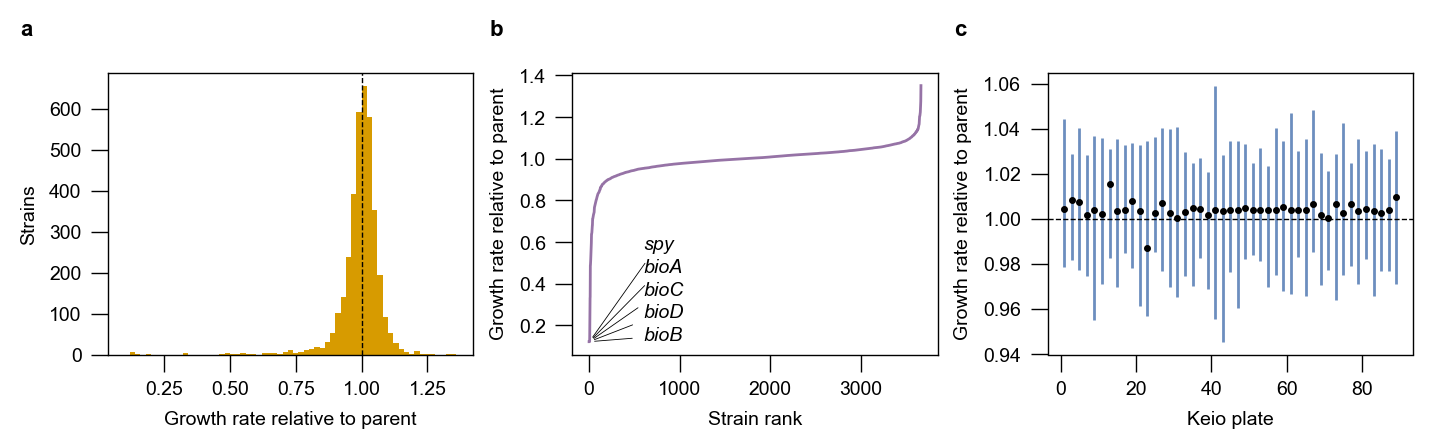

In [7]:
figure, (left, middle, right) = three_panels()
left.hist(growth_table["fitness"], bins=np.arange(0.10, 1.38, 0.02), color=ORANGE)
left.axvline(1.0, color="black", linewidth=0.5, linestyle="--")
left.set(xlabel="Growth rate relative to parent", ylabel="Strains")

ranked = growth_table.sort_values("fitness").reset_index(drop=True)
middle.plot(ranked.index + 1, ranked["fitness"], color=PURPLE, linewidth=1)
for rank, row in ranked.head(5).iterrows():
    middle.annotate(
        row["gene"],
        (rank + 1, row["fitness"]),
        xytext=(600, 0.15 + 0.11 * rank),
        fontstyle="italic",
        va="center",
        arrowprops={"arrowstyle": "-", "linewidth": 0.3},
    )
middle.set(xlabel="Strain rank", ylabel="Growth rate relative to parent")

plates = growth_table.groupby("plate")["fitness"].quantile([0.25, 0.5, 0.75]).unstack()
right.vlines(plates.index, plates[0.25], plates[0.75], color=BLUE, linewidth=1)
right.plot(plates.index, plates[0.5], "o", color="black", markersize=1.5)
right.axhline(1.0, color="black", linewidth=0.5, linestyle="--")
right.set(xlabel="Keio plate", ylabel="Growth rate relative to parent")
save(figure, "ecoli_growth_rate_campos2018")
from IPython.display import Image

Image(str(FIGURES / "ecoli_growth_rate_campos2018.png"))

### The same record as typed objects

`transform_item` validates a record through the pydantic classes of the schema.

In [8]:
typed = growth.transform_item(record)  # the same record as validated pydantic objects
experiment = typed["experiment"]
print(type(experiment).__name__, type(experiment.phenotype).__name__)
print(
    experiment.genotype.perturbations[0].perturbed_gene_name,
    experiment.phenotype.fitness,
)

FitnessExperiment FitnessPhenotype
hchA 1.0201256910920211


## Cell shape and cell cycle (Campos 2018)

The same strains from the same imaging screen, with cell-shape means and cell-cycle features.

In [9]:
started = time.perf_counter()
morphology = MorphologyCampos2018Dataset(root=str(DATA / "ecoli_morphology_campos2018"))
SECONDS["ecoli_morphology_campos2018"] = time.perf_counter() - started
print(f"{len(morphology):,} records")

phenotype = morphology[0]["experiment"]["phenotype"]
print("cells measured", phenotype["n_samples"])
print("features      ", list(phenotype["morphology"]))

3,664 records
cells measured 245
features       ['<L>', '<W>', '<A>', '<V>', '<SA>', '<P>', '<C>', '<Ar>', '<SA/V>', '<NA>', 'rho_CD', 'CDN_C0', 'Rel.timing div', 'Rel.timing nuc', '%2N']


In [10]:
morphology_table = pd.DataFrame(
    {
        "gene": r["experiment"]["genotype"]["perturbations"][0]["perturbed_gene_name"],
        **r["experiment"]["phenotype"]["morphology"],
    }
    for r in (morphology[i] for i in range(len(morphology)))
).set_index("gene")
print("table shape   ", morphology_table.shape)
print(
    "features per strain:",
    morphology_table.notna().sum(axis=1).value_counts().to_dict(),
)
unit = FEATURE_UNITS.value  # feature symbol -> unit, as the release states it
print("units         ", {symbol: unit[symbol] for symbol in ("<L>", "<W>", "<A>")})
shown = ["<L>", "<W>", "<A>", "<SA/V>", "rho_CD", "%2N"]
print(morphology_table[shown].head(6).to_string(float_format="{:.4f}".format))

table shape    (3664, 15)
features per strain: {15: 3422, 9: 242}
units          {'<L>': 'µm', '<W>': 'µm', '<A>': 'µm2'}
        <L>    <W>    <A>  <SA/V>  rho_CD    %2N
gene                                            
hchA 3.1955 1.1731 3.2340  4.2067  0.1753 0.3315
bglG 3.1495 1.1772 3.1965  4.1760  0.4017 0.2691
cytR 3.1203 1.2074 3.2240  4.1018  0.5403 0.2903
fnr  3.1126 1.1413 3.0587  4.2452  0.5705 0.3047
hupB 3.3444 1.0857 3.1668  4.3908  0.5330 0.2058
nagC 3.1478 1.1609 3.1520  4.2069  0.7041 0.2982


The growth-rate dataset holds the same strains in the same order.

In [11]:
# The two Campos 2018 datasets hold the same strains in the same order, so the growth
# rate of each strain sits beside its cell shape.
assert list(morphology_table.index) == list(growth_table["gene"])
shape_growth = morphology_table.assign(fitness=growth_table["fitness"].to_numpy())
rank_correlation = shape_growth["<A>"].rank().corr(shape_growth["fitness"].rank())
print(f"strains {len(shape_growth):,}")
print(f"Spearman correlation of cell area with growth rate {rank_correlation:.3f}")

strains 3,664
Spearman correlation of cell area with growth rate 0.095


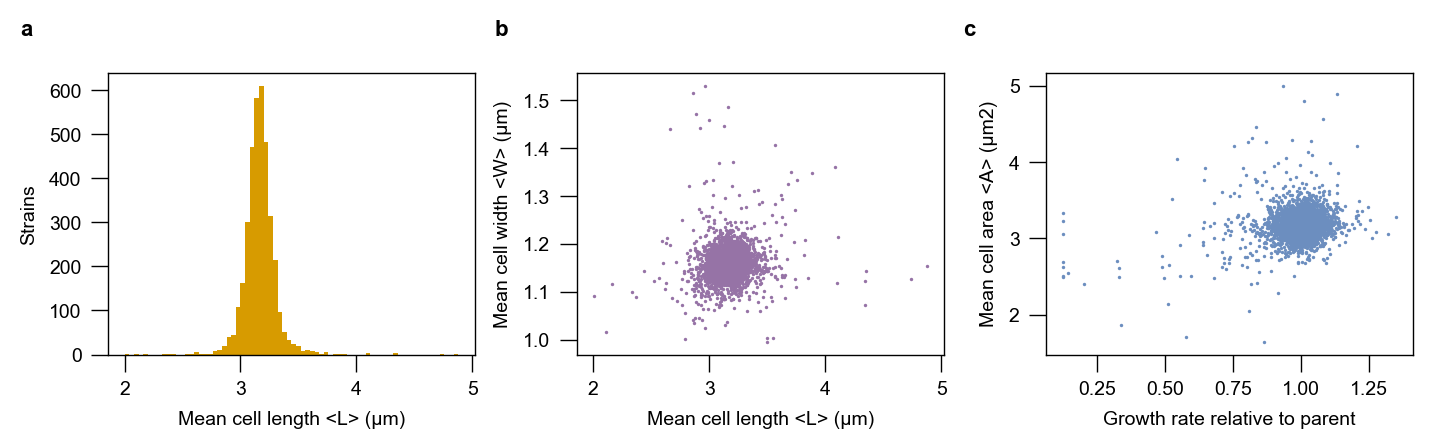

In [12]:
figure, (left, middle, right) = three_panels()
left.hist(morphology_table["<L>"], bins=np.arange(2.0, 4.92, 0.04), color=ORANGE)
left.set(xlabel=f"Mean cell length <L> ({unit['<L>']})", ylabel="Strains")

middle.scatter(
    morphology_table["<L>"],
    morphology_table["<W>"],
    s=1.5,
    color=PURPLE,
    linewidths=0,
    rasterized=True,
)
middle.set(
    xlabel=f"Mean cell length <L> ({unit['<L>']})",
    ylabel=f"Mean cell width <W> ({unit['<W>']})",
)

right.scatter(
    shape_growth["fitness"],
    shape_growth["<A>"],
    s=1.5,
    color=BLUE,
    linewidths=0,
    rasterized=True,
)
right.set(
    xlabel="Growth rate relative to parent",
    ylabel=f"Mean cell area <A> ({unit['<A>']})",
)
save(figure, "ecoli_morphology_campos2018")
from IPython.display import Image

Image(str(FIGURES / "ecoli_morphology_campos2018.png"))

## Genetic interactions (Babu 2014)

One record per double mutant of the released high-confidence set. The label is the pair's S-score.

In [13]:
started = time.perf_counter()
interaction = GeneInteractionBabu2014Dataset(
    root=str(DATA / "gene_interaction_babu2014")
)
SECONDS["gene_interaction_babu2014"] = time.perf_counter() - started
print(f"{len(interaction):,} records")

record = interaction[0]
phenotype = record["experiment"]["phenotype"]
for perturbation in record["experiment"]["genotype"]["perturbations"]:
    print(
        "gene   ",
        perturbation["perturbed_gene_name"],
        perturbation["systematic_gene_name"],
        "|",
        perturbation["collection"],
    )
print(
    "S-score", phenotype["gene_interaction"], "from", phenotype["n_samples"], "colonies"
)
print("medium ", record["experiment"]["environment"]["media"]["name"])

42,705 records
gene    thrA b0002 | Hfr Cavalli (Hfr C) donor query strains
gene    dnaJ b0015 | Keio collection
S-score -4.43348 from 8 colonies
medium  LB with kanamycin and chloramphenicol, amounts not stated (Babu 2014), solid


In [14]:
rows = []
for r in (interaction[i] for i in range(len(interaction))):
    first, second = r["experiment"]["genotype"]["perturbations"]
    rows.append(
        {
            "gene_a": first["perturbed_gene_name"],
            "gene_b": second["perturbed_gene_name"],
            "id_a": first["systematic_gene_name"],
            "id_b": second["systematic_gene_name"],
            "s_score": r["experiment"]["phenotype"]["gene_interaction"],
        }
    )
pairs = pd.DataFrame(rows)
print(pairs.head(6).to_string(index=False, float_format="{:.4f}".format))
print("genes in any pair:", len(interaction.gene_set))
print("negative scores:", int((pairs["s_score"] < 0).sum()))
print("positive scores:", int((pairs["s_score"] > 0).sum()))
print("strongest negative pairs:")
print(
    pairs.nsmallest(3, "s_score").to_string(index=False, float_format="{:.4f}".format)
)

gene_a gene_b  id_a  id_b  s_score
  thrA   dnaJ b0002 b0015  -4.4335
  thrA   caiE b0002 b0035  -4.1931
  thrA   sfsA b0002 b0146   4.2653
  thrA   ligT b0002 b0147  -5.2363
  thrA   yaeQ b0002 b0190   4.9501
  thrA   metN b0002 b0199   4.2045
genes in any pair: 3880
negative scores: 25239
positive scores: 17466
strongest negative pairs:
gene_a gene_b  id_a  id_b  s_score
  oppA   topA b1243 b1274 -30.9240
   tig   accD b0436 b2316 -28.1061
  sufC    fdx b1682 b2525 -24.9893


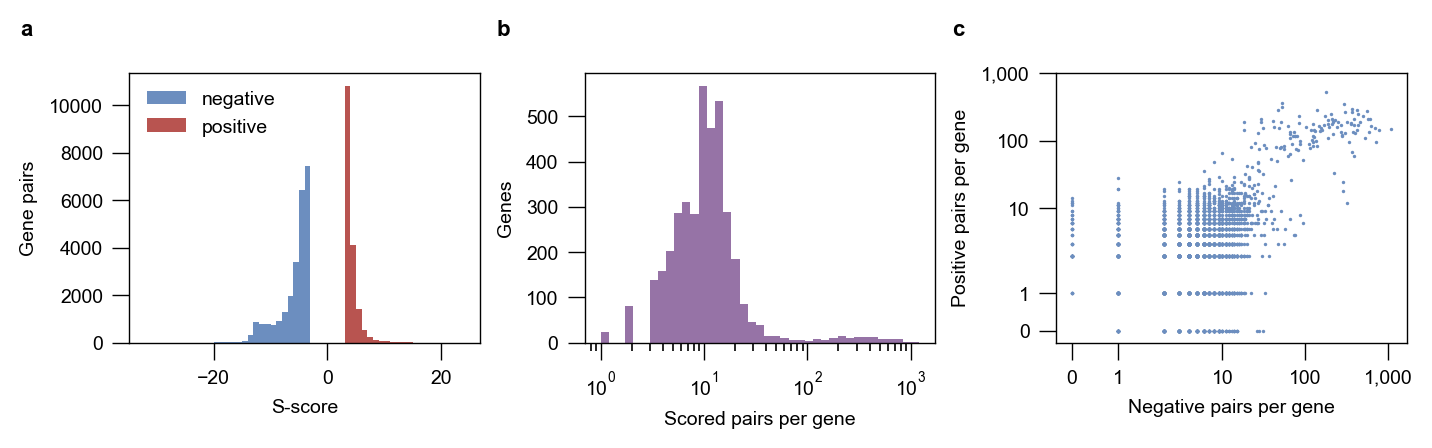

In [15]:
figure, (left, middle, right) = three_panels()
edges = np.arange(-32, 25, 1)
negative = pairs["s_score"] < 0
left.hist(pairs.loc[negative, "s_score"], bins=edges, color=BLUE, label="negative")
left.hist(pairs.loc[~negative, "s_score"], bins=edges, color=RED, label="positive")
left.set(xlabel="S-score", ylabel="Gene pairs")
left.legend()

# One row per gene: how many of its pairs score below zero and how many above.
per_gene = (
    pd.concat(
        [
            pairs[["id_a", "s_score"]].rename(columns={"id_a": "id"}),
            pairs[["id_b", "s_score"]].rename(columns={"id_b": "id"}),
        ]
    )
    .assign(negative=lambda t: t["s_score"] < 0, positive=lambda t: t["s_score"] > 0)
    .groupby("id")[["negative", "positive"]]
    .sum()
)
degree = per_gene["negative"] + per_gene["positive"]
middle.hist(degree, bins=np.logspace(0, np.log10(degree.max() + 1), 40), color=PURPLE)
middle.set(xscale="log", xlabel="Scored pairs per gene", ylabel="Genes")

right.scatter(
    per_gene["negative"],
    per_gene["positive"],
    s=1.5,
    color=BLUE,
    linewidths=0,
    rasterized=True,
)
right.set(
    xscale="symlog",
    yscale="symlog",
    xlabel="Negative pairs per gene",
    ylabel="Positive pairs per gene",
)
for axis in (right.xaxis, right.yaxis):  # linear from 0 to 1, logarithmic above
    axis.set_ticks([0, 1, 10, 100, 1000], labels=["0", "1", "10", "100", "1,000"])
    axis.minorticks_off()
save(figure, "gene_interaction_babu2014")
from IPython.display import Image

Image(str(FIGURES / "gene_interaction_babu2014.png"))

## Metabolome (Fuhrer 2017)

One record per Keio strain. The label maps each detected ion to a modified z-score.

In [16]:
started = time.perf_counter()
metabolome = MetabolomeFuhrer2017Dataset(root=str(DATA / "metabolome_fuhrer2017"))
SECONDS["metabolome_fuhrer2017"] = time.perf_counter() - started
print(f"{len(metabolome):,} records")

record = metabolome[0]
levels = record["experiment"]["phenotype"]["metabolite_level"]  # ion key -> z-score
print(
    "strain      ", record["experiment"]["genotype"]["perturbations"][0]["strain_label"]
)
print("ions        ", len(levels))
print("first ions  ", dict(list(levels.items())[:4]))

ions = pd.read_csv(Path(metabolome.preprocess_dir) / "ions.csv")  # ion key -> m/z
print(ions.head(4).to_string(index=False, float_format="{:.5f}".format))

3,806 records
strain       aaeA
ions         7534
first ions   {'neg_0001': -0.4309, 'neg_0002': -0.1195, 'neg_0003': -0.6621, 'neg_0004': 0.9284}
     key mode  ion_index  deposit_mz  table_ev1b_mz
neg_0001  neg          1    56.99716       56.99624
neg_0002  neg          2    57.03575       57.03483
neg_0003  neg          3    57.05741       57.05649
neg_0004  neg          4    58.03895       58.03803


In [17]:
ion_keys = list(levels)
strains, matrix_rows = [], []
for r in (metabolome[i] for i in range(len(metabolome))):
    perturbations = r["experiment"]["genotype"]["perturbations"]
    strains.append("+".join(p["perturbed_gene_name"] for p in perturbations))
    row_levels = r["experiment"]["phenotype"]["metabolite_level"]
    matrix_rows.append([row_levels[key] for key in ion_keys])
matrix = np.asarray(matrix_rows, dtype=np.float32)  # strains x ions
print("matrix shape", matrix.shape, matrix.dtype)
corner = pd.DataFrame(matrix[:5, :5], index=strains[:5], columns=ion_keys[:5])
print(corner.to_string(float_format="{:.4f}".format))
print("z-scores beyond 5 in absolute value:", int((np.abs(matrix) > 5).sum()))
print("records that name more than one gene:", sum("+" in name for name in strains))

matrix shape (3806, 7534) float32
      neg_0001  neg_0002  neg_0003  neg_0004  neg_0005
aaeA   -0.4309   -0.1195   -0.6621    0.9284   -0.6906
aaeB   -1.8696    1.1863    1.7171    0.3849    0.7550
aaeR    1.3402   -0.8219    1.0256    2.0786   -0.5455
aaeX    0.2608   -0.5211    0.0221   -0.8930    0.4659
aas     1.1950    0.2000   -0.4579    0.8433    0.5156
z-scores beyond 5 in absolute value: 31863
records that name more than one gene: 21


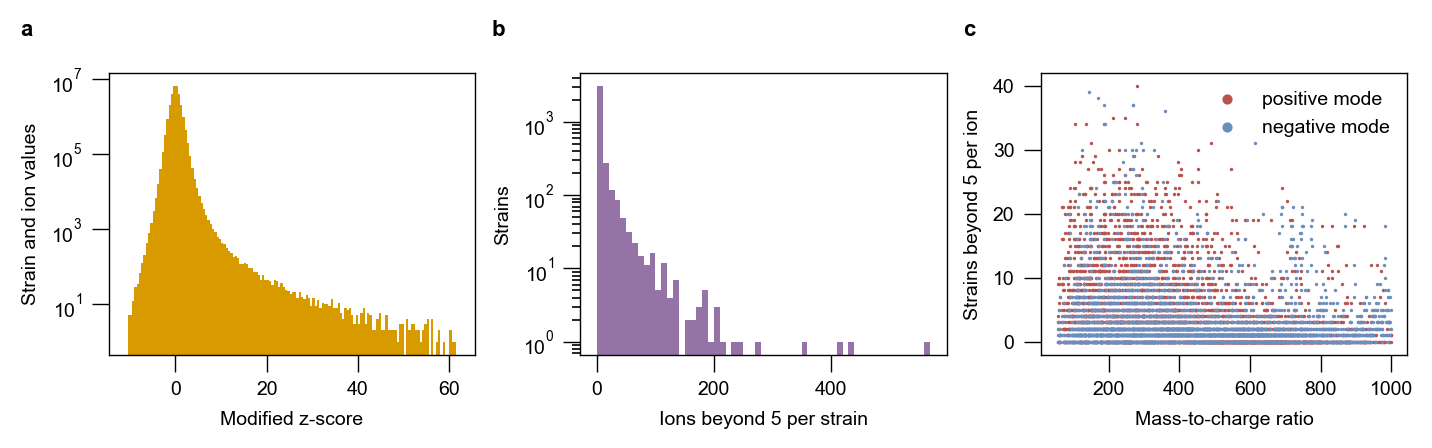

In [18]:
figure, (left, middle, right) = three_panels()
left.hist(matrix.ravel(), bins=np.arange(-11.0, 62.5, 0.5), color=ORANGE)
left.set(yscale="log", xlabel="Modified z-score", ylabel="Strain and ion values")

beyond = np.abs(matrix) > 5
middle.hist(beyond.sum(axis=1), bins=np.arange(0, 580, 10), color=PURPLE)
middle.set(yscale="log", xlabel="Ions beyond 5 per strain", ylabel="Strains")

for mode, color in (("pos", RED), ("neg", BLUE)):
    of_mode = (ions["mode"] == mode).to_numpy()
    right.scatter(
        ions.loc[of_mode, "deposit_mz"],
        beyond.sum(axis=0)[of_mode],
        s=1.5,
        color=color,
        linewidths=0,
        rasterized=True,
        label={"neg": "negative mode", "pos": "positive mode"}[mode],
    )
right.set(xlabel="Mass-to-charge ratio", ylabel="Strains beyond 5 per ion")
right.legend(markerscale=3, loc="upper right")
save(figure, "metabolome_fuhrer2017")
from IPython.display import Image

Image(str(FIGURES / "metabolome_fuhrer2017.png"))

## Check the records against the release

Hashing the loaded records reproduces the content hash the knowledge-graph release recorded.

In [19]:
def experiment_id(record: dict[str, Any]) -> str:
    """The id the knowledge graph gives this record: sha256 of its experiment."""
    return hashlib.sha256(json.dumps(record["experiment"]).encode("utf-8")).hexdigest()


loaded = {
    "ecoli_growth_rate_campos2018": growth,
    "ecoli_morphology_campos2018": morphology,
    "gene_interaction_babu2014": interaction,
    "metabolome_fuhrer2017": metabolome,
}
for slug, dataset in loaded.items():
    ids = (experiment_id(dataset[i]) for i in range(len(dataset)))
    digest = content_sha256(ids)  # one hash over every record of the dataset
    served = client.select(slug).content_sha256  # what the release recorded
    print(
        f"{slug}  {digest}  {'matches' if digest == served else 'DIFFERS FROM'} the release"
    )

ecoli_growth_rate_campos2018  a8ced65c7e68b1d673ad404f001dc47fb9807db7cc3b131282bf532d10f7e11c  matches the release
ecoli_morphology_campos2018  15d7c23e9300015d48426f8b7e813aec540bd5a9854e8392b7ab1eef19836e6b  matches the release
gene_interaction_babu2014  fb1f87b2c861a2df6e06bfe8abdcb71bbd46ff77fe56ba2c53996a65f2584f10  matches the release
metabolome_fuhrer2017  adeb2d85353f426d3a775eab4c09e99e97c47b9c3b96be6684c54cfa6d2162bd  matches the release
